In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROCESSED = Path("../data/processed")
REPORTS = Path("../reports")
REPORTS.mkdir(exist_ok=True)

mart = pd.read_parquet(
    PROCESSED / "mart_manufacturer_drug_month.parquet"
)

mart["event_month"] = pd.to_datetime(mart["event_month"])
mart = mart.sort_values(["manufacturer", "drug_name", "event_month"])

print(mart.shape)
mart.head()

(1362400, 21)


,manufacturer,drug_name,event_month,events_count,batches_count,letters_count,regions_affected,first_event_date,last_event_date,events_lag_1m,...,events_lag_6m,events_rolling_3m,events_rolling_6m,events_rolling_12m,events_rolling_3m_mean,events_rolling_12m_mean,risk_flag_spike,risk_flag_repeated,risk_flag_active_month,risk_score_v0
0,,аримидекс,2005-01-01,0.0,0.0,0.0,0.0,NaT,NaT,NaN,...,NaN,0.0,0.0,0.0,0.0,0.0,0,0,0,0
1,,аримидекс,2005-02-01,0.0,0.0,0.0,0.0,NaT,NaT,0.0,...,NaN,0.0,0.0,0.0,0.0,0.0,0,0,0,0
2,,аримидекс,2005-03-01,0.0,0.0,0.0,0.0,NaT,NaT,0.0,...,NaN,0.0,0.0,0.0,0.0,0.0,0,0,0,0
3,,аримидекс,2005-04-01,0.0,0.0,0.0,0.0,NaT,NaT,0.0,...,NaN,0.0,0.0,0.0,0.0,0.0,0,0,0,0
4,,аримидекс,2005-05-01,0.0,0.0,0.0,0.0,NaT,NaT,0.0,...,NaN,0.0,0.0,0.0,0.0,0.0,0,0,0,0


In [2]:
MIN_HISTORY_MONTHS = 12
MIN_HISTORICAL_EVENTS = 2

pair_history = (
    mart.groupby(["manufacturer", "drug_name"])["events_count"]
    .agg(
        total_events="sum",
        active_months=lambda s: (s > 0).sum(),
        history_months="size",
    )
    .reset_index()
)

eligible_pairs = pair_history[
    (pair_history["history_months"] >= MIN_HISTORY_MONTHS)
    & (pair_history["total_events"] >= MIN_HISTORICAL_EVENTS)
]

mart_scored = mart.merge(
    eligible_pairs[["manufacturer", "drug_name"]],
    on=["manufacturer", "drug_name"],
    how="inner",
)

print("Все пары:", pair_history.shape[0])
print("Пары с достаточной историей:", eligible_pairs.shape[0])
print("Строк для скоринга:", mart_scored.shape[0])

Все пары: 5200
Пары с достаточной историей: 3238
Строк для скоринга: 848356


In [3]:
def add_robust_anomaly_features(df: pd.DataFrame) -> pd.DataFrame:
    df = df.sort_values(["manufacturer", "drug_name", "event_month"]).copy()

    grouped = df.groupby(["manufacturer", "drug_name"], group_keys=False)

    df["events_baseline_median_12m"] = (
        grouped["events_count"]
        .transform(lambda s: s.shift(1).rolling(12, min_periods=6).median())
    )

    df["events_baseline_mad_12m"] = (
        grouped["events_count"]
        .transform(
            lambda s: s.shift(1)
            .rolling(12, min_periods=6)
            .apply(lambda x: np.median(np.abs(x - np.median(x))), raw=True)
        )
    )

    df["events_zscore_robust_12m"] = (
        (df["events_count"] - df["events_baseline_median_12m"])
        / (1.4826 * df["events_baseline_mad_12m"])
    )

    df["events_ratio_to_median_12m"] = (
        df["events_count"] / df["events_baseline_median_12m"].replace(0, np.nan)
    )

    df["anomaly_flag_robust"] = (
        (df["events_zscore_robust_12m"] >= 3.5)
        & (df["events_count"] >= 2)
    ).astype(int)

    return df

mart_scored = add_robust_anomaly_features(mart_scored)

mart_scored[
    [
        "manufacturer",
        "drug_name",
        "event_month",
        "events_count",
        "events_baseline_median_12m",
        "events_baseline_mad_12m",
        "events_zscore_robust_12m",
        "events_ratio_to_median_12m",
        "anomaly_flag_robust",
    ]
].head(20)

,manufacturer,drug_name,event_month,events_count,events_baseline_median_12m,events_baseline_mad_12m,events_zscore_robust_12m,events_ratio_to_median_12m,anomaly_flag_robust
0,,карсил,2005-01-01,0.0,NaN,NaN,NaN,NaN,0
1,,карсил,2005-02-01,0.0,NaN,NaN,NaN,NaN,0
2,,карсил,2005-03-01,0.0,NaN,NaN,NaN,NaN,0
3,,карсил,2005-04-01,1.0,NaN,NaN,NaN,NaN,0
4,,карсил,2005-05-01,0.0,NaN,NaN,NaN,NaN,0
5,,карсил,2005-06-01,1.0,NaN,NaN,NaN,NaN,0
6,,карсил,2005-07-01,0.0,0.0,NaN,NaN,NaN,0
7,,карсил,2005-08-01,0.0,0.0,NaN,NaN,NaN,0
8,,карсил,2005-09-01,0.0,0.0,NaN,NaN,NaN,0
9,,карсил,2005-10-01,1.0,0.0,NaN,NaN,NaN,0


In [4]:
mart_scored["risk_score_anomaly"] = (
    0.45 * mart_scored["events_zscore_robust_12m"].clip(lower=0)
    + 0.25 * mart_scored["events_ratio_to_median_12m"].clip(lower=0, upper=10)
    + 0.15 * mart_scored["events_rolling_3m"]
    + 0.10 * mart_scored["events_rolling_6m"]
    + 0.05 * mart_scored["events_rolling_12m"]
)

mart_scored["risk_flag_anomaly"] = mart_scored["anomaly_flag_robust"]

In [5]:
last_month = mart_scored["event_month"].max()

top_risk = (
    mart_scored[mart_scored["event_month"] == last_month]
    .sort_values(["risk_score_anomaly", "events_count"], ascending=[False, False])
    .head(20)
)

top_risk[
    [
        "event_month",
        "manufacturer",
        "drug_name",
        "events_count",
        "events_rolling_3m",
        "events_baseline_median_12m",
        "events_zscore_robust_12m",
        "events_ratio_to_median_12m",
        "risk_score_anomaly",
        "risk_flag_anomaly",
    ]
]

,event_month,manufacturer,drug_name,events_count,events_rolling_3m,events_baseline_median_12m,events_zscore_robust_12m,events_ratio_to_median_12m,risk_score_anomaly,risk_flag_anomaly
478935,2026-10-01,"общество с ограниченной ответственностью ""пран...",амлодипин-прана,0.0,8.0,2.0,-0.674491,0.0,4.2,0
479459,2026-10-01,"общество с ограниченной ответственностью ""пран...",бетагистин,0.0,0.0,2.5,-0.674491,0.0,3.1,0
456665,2026-10-01,"общество с ограниченной ответственностью ""велф...",ибупрофен велфарм,1.0,3.0,0.0,inf,NaN,NaN,0
482865,2026-10-01,"общество с ограниченной ответственностью ""прои...",симетикон,1.0,2.0,0.0,inf,NaN,NaN,0
587141,2026-10-01,"публичное акционерное общество ""акционерное ку...",кеторолак,1.0,6.0,0.0,inf,NaN,NaN,0
261,2026-10-01,,карсил,0.0,0.0,0.0,NaN,NaN,NaN,0
523,2026-10-01,,лома люкс псориасис,0.0,0.0,0.0,NaN,NaN,NaN,0
785,2026-10-01,,салициловая кислота,0.0,0.0,0.0,NaN,NaN,NaN,0
1047,2026-10-01,"""астеллас фарма юроп б.в."", нидерланды",везикар,0.0,0.0,0.0,NaN,NaN,NaN,0
1309,2026-10-01,"""ауробиндо фарма лтд""",ампициллин натрия,0.0,0.0,0.0,NaN,NaN,NaN,0


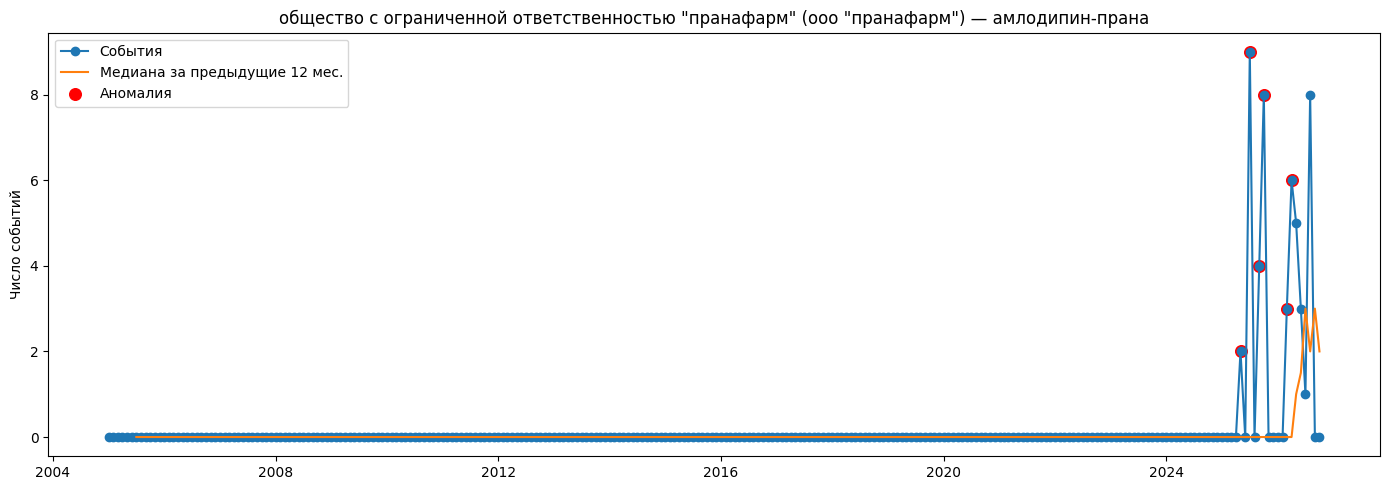

In [9]:
example = top_risk.iloc[0]
mask = (
    (mart_scored["manufacturer"] == example["manufacturer"])
    & (mart_scored["drug_name"] == example["drug_name"])
)

pair_df = mart_scored[mask].set_index("event_month")

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(
    pair_df.index,
    pair_df["events_count"],
    marker="o",
    label="События",
)
ax.plot(
    pair_df.index,
    pair_df["events_baseline_median_12m"],
    label="Медиана за предыдущие 12 мес.",
)
anomalies = pair_df[pair_df["anomaly_flag_robust"] == 1]
ax.scatter(
    anomalies.index,
    anomalies["events_count"],
    color="red",
    s=70,
    label="Аномалия",
)

ax.set_title(
    f"{example['manufacturer']} — {example['drug_name']}"
)
ax.set_ylabel("Число событий")
ax.legend()
fig.tight_layout()
fig.savefig(
    REPORTS / "anomaly_example.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()

In [11]:
pip install -U scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.2/9.2 MB 3.1 MB/s  0:00:03 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [scikit-learn] [scikit-learn]
Note: you may need to restart the kernel to use updated packages.


In [12]:
from sklearn.ensemble import IsolationForest

feature_cols = [
    "events_count",
    "batches_count",
    "letters_count",
    "regions_affected",
    "events_rolling_3m",
    "events_rolling_6m",
    "events_rolling_12m",
    "events_rolling_3m_mean",
    "events_rolling_12m_mean",
    "events_ratio_to_median_12m",
]

features = mart_scored[feature_cols].fillna(0)

iso = IsolationForest(
    n_estimators=300,
    contamination=0.02,
    random_state=42,
    n_jobs=-1,
)

mart_scored["isolation_forest_score"] = -iso.fit(features).score_samples(features)
mart_scored["anomaly_flag_isolation_forest"] = (
    iso.predict(features) == -1
).astype(int)

In [15]:
N_TOP = 5000

mart_scored["if_rank"] = mart_scored["isolation_forest_score"].rank(
    ascending=False,
    method="first",
)

mart_scored["anomaly_flag_if_top5000"] = (
    mart_scored["if_rank"] <= N_TOP
).astype(int)

comparison = pd.DataFrame(
    {
        "method": ["robust_rule", "isolation_forest_top_5000"],
        "alerts": [
            mart_scored["anomaly_flag_robust"].sum(),
            mart_scored["anomaly_flag_if_top5000"].sum(),
        ],
    }
)

comparison["overlap"] = (
    (mart_scored["anomaly_flag_robust"] == 1)
    & (mart_scored["anomaly_flag_if_top5000"] == 1)
).sum()

comparison["overlap_share_of_robust"] = (
    comparison.loc[0, "overlap"]
    / comparison.loc[0, "alerts"]
)

comparison

,method,alerts,overlap,overlap_share_of_robust
0,robust_rule,4029,2626,0.651775
1,isolation_forest_top_5000,5000,2626,0.651775


In [16]:
top_if = (
    mart_scored.sort_values("isolation_forest_score", ascending=False)
    .head(20)
)

top_if[
    [
        "event_month",
        "manufacturer",
        "drug_name",
        "events_count",
        "events_rolling_3m",
        "events_baseline_median_12m",
        "events_zscore_robust_12m",
        "events_ratio_to_median_12m",
        "isolation_forest_score",
        "anomaly_flag_robust",
    ]
]

,event_month,manufacturer,drug_name,events_count,events_rolling_3m,events_baseline_median_12m,events_zscore_robust_12m,events_ratio_to_median_12m,isolation_forest_score,anomaly_flag_robust
479182,2025-07-01,"общество с ограниченной ответственностью ""пран...",аторвастатин,103.0,116.0,1.0,68.798057,103.000000,0.882746,1
574526,2023-07-01,"пао ""биосинтез""",эналаприл,362.0,434.0,0.5,487.656819,724.000000,0.881751,1
404399,2016-02-01,никомед гмбх,кардиомагнил,1104.0,1142.0,0.5,1488.601106,2208.000000,0.881751,1
97920,2021-03-01,балканфарма - троян ад,алмагель,48.0,76.0,0.5,64.076622,96.000000,0.879567,1
809642,2010-03-01,шрея лайф сайенсиз пвт.лтд,суприма-лор,24.0,42.0,4.5,3.288142,5.333333,0.878972,0
809643,2010-04-01,шрея лайф сайенсиз пвт.лтд,суприма-лор,16.0,51.0,6.0,1.927116,2.666667,0.878972,0
564849,2024-12-01,"открытое акционерное общество ""фармстандарт-уф...",аскорбиновая кислота с глюкозой,21.0,49.0,3.5,3.372454,6.000000,0.878972,0
479184,2025-09-01,"общество с ограниченной ответственностью ""пран...",аторвастатин,11.0,114.0,2.5,2.293269,4.400000,0.878774,0
636076,2021-11-01,санека фармасьютикалс а.с.,лозап,672.0,672.0,0.0,inf,NaN,0.878575,1
285100,2008-09-01,йодные технологии и маркетинг ооо,аммиак,17.0,25.0,2.5,3.912046,6.800000,0.878575,1


In [19]:
def fit_isolation_forest_once(
    df: pd.DataFrame,
    train_end_month: str = "2024-12",
) -> pd.DataFrame:
    df = df.sort_values(["event_month"]).copy()
    df["isolation_forest_score"] = np.nan

    feature_cols = [
        "events_count",
        "batches_count",
        "letters_count",
        "regions_affected",
        "events_rolling_3m",
        "events_rolling_6m",
        "events_rolling_12m",
        "events_rolling_3m_mean",
        "events_rolling_12m_mean",
        "events_ratio_to_median_12m",
    ]

    train_cutoff = pd.Timestamp(train_end_month + "-01")

    train = df[df["event_month"] <= train_cutoff]
    score = df[df["event_month"] > train_cutoff]

    if len(train) < 100:
        raise ValueError("Недостаточно исторических данных для обучения")

    iso = IsolationForest(
        n_estimators=120,
        max_samples=256,
        contamination="auto",
        random_state=42,
        n_jobs=2,
    )

    iso.fit(train[feature_cols].fillna(0))

    df.loc[score.index, "isolation_forest_score"] = -iso.score_samples(
        score[feature_cols].fillna(0)
    )

    return df

mart_scored = fit_isolation_forest_once(
    mart_scored,
    train_end_month="2024-12",
)

In [20]:
mart_scored["if_score_percentile"] = mart_scored[
    "isolation_forest_score"
].rank(pct=True)

mart_scored["risk_score_v1"] = (
    0.40 * mart_scored["events_zscore_robust_12m"].clip(lower=0)
    + 0.25 * mart_scored["events_ratio_to_median_12m"].clip(lower=0, upper=10)
    + 0.20 * mart_scored["if_score_percentile"]
    + 0.10 * mart_scored["events_rolling_3m"]
    + 0.05 * mart_scored["events_rolling_6m"]
)

In [22]:
mart_scored.describe()

/home/alex/quality-risk-radar/.venv/lib/python3.12/site-packages/numpy/_core/_methods.py:51: RuntimeWarning: invalid value encountered in reduce
  return umr_sum(a, axis, dtype, out, keepdims, initial, where)
/home/alex/quality-risk-radar/.venv/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:4671: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)
/home/alex/quality-risk-radar/.venv/lib/python3.12/site-packages/pandas/core/nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)


,event_month,events_count,batches_count,letters_count,regions_affected,first_event_date,last_event_date,events_lag_1m,events_lag_3m,events_lag_6m,...,events_ratio_to_median_12m,anomaly_flag_robust,risk_score_anomaly,risk_flag_anomaly,isolation_forest_score,anomaly_flag_isolation_forest,if_rank,anomaly_flag_if_top5000,if_score_percentile,risk_score_v1
count,848356,848356.000000,848356.000000,848356.000000,848356.000000,13115,13115,845118.000000,838642.000000,828928.000000,...,3185.000000,848356.000000,3142.000000,848356.000000,71236.000000,848356.000000,848356.000000,848356.000000,71236.000000,99.000000
mean,2015-11-16 00:32:58.625953792,0.047139,0.041721,0.020919,0.015462,2013-02-10 13:05:03.316813056,2013-02-12 16:55:37.857415168,0.047316,0.047626,0.048022,...,2.209370,0.004749,inf,0.004749,0.344730,0.020001,424178.500000,0.005894,0.500007,2.917558
min,2005-01-01 00:00:00,0.000000,0.000000,0.000000,0.000000,2005-01-17 00:00:00,2005-01-17 00:00:00,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.250000,0.000000,0.336562,0.000000,1.000000,0.000000,0.487394,0.198308
25%,2010-06-01 00:00:00,0.000000,0.000000,0.000000,0.000000,2008-12-05 00:00:00,2008-12-08 00:00:00,0.000000,0.000000,0.000000,...,0.000000,0.000000,1.200000,0.000000,0.336562,0.000000,212089.750000,0.000000,0.487394,0.724013
50%,2015-11-16 00:00:00,0.000000,0.000000,0.000000,0.000000,2011-11-18 00:00:00,2011-11-18 00:00:00,0.000000,0.000000,0.000000,...,0.000000,0.000000,2.200000,0.000000,0.336562,0.000000,424178.500000,0.000000,0.487394,1.599698
75%,2021-05-01 00:00:00,0.000000,0.000000,0.000000,0.000000,2016-10-10 00:00:00,2016-10-11 00:00:00,0.000000,0.000000,0.000000,...,1.333333,0.000000,4.209682,0.000000,0.336562,0.000000,636267.250000,0.000000,0.487394,2.924808
max,2026-10-01 00:00:00,1140.000000,570.000000,20.000000,2.000000,2026-10-08 00:00:00,2026-10-08 00:00:00,1140.000000,1140.000000,1140.000000,...,2208.000000,1.000000,inf,1.000000,0.876399,1.000000,848356.000000,1.000000,1.000000,47.919223
std,NaN,2.288937,1.585827,0.204469,0.123399,NaN,NaN,2.293315,2.302104,2.315176,...,41.492218,0.068751,NaN,0.068751,0.053492,0.140004,244899.426822,0.076544,0.078415,5.534470


In [23]:
print(mart_scored["isolation_forest_score"].notna().sum())
print(mart_scored["isolation_forest_score"].describe())
print(mart_scored["event_month"].min(), mart_scored["event_month"].max())

71236
count    71236.000000
mean         0.344730
std          0.053492
min          0.336562
25%          0.336562
50%          0.336562
75%          0.336562
max          0.876399
Name: isolation_forest_score, dtype: float64
2005-01-01 00:00:00 2026-10-01 00:00:00
